In [1]:
!pip install pandas numpy matplotlib seaborn scipy scikit-learn scikit-surprise

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ------------------------------- -------- 1.0/1.3 MB 8.4 MB/s eta 0:00:01
   ---------------------------------------- 1.3/1.3 MB 7.6 MB/s eta 0:00:00


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [3]:
import surprise
print("Surprise installed successfully!")


Surprise installed successfully!


In [5]:
from surprise import Dataset, Reader, SVD
print("Library working correctly!")

Library working correctly!


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer

In [11]:
import pandas as pd

books = pd.read_csv("books.csv")
ratings = pd.read_csv("Ratings.csv")
users = pd.read_csv("Users.csv")

print("Books Shape:", books.shape)
print("Ratings Shape:", ratings.shape)
print("Users Shape:", users.shape)

C:\Users\alekh\AppData\Local\Temp\ipykernel_24776\2779687882.py:3: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  books = pd.read_csv("books.csv")


Books Shape: (271360, 8)
Ratings Shape: (1149780, 3)
Users Shape: (278858, 3)


In [13]:
books = pd.read_csv("books.csv", low_memory=False)

In [15]:
print(books.columns)
print(ratings.columns)
print(users.columns)

Index(['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher',
       'Image-URL-S', 'Image-URL-M', 'Image-URL-L'],
      dtype='object')
Index(['User-ID', 'ISBN', 'Book-Rating'], dtype='object')
Index(['User-ID', 'Location', 'Age'], dtype='object')


In [17]:
# Merge Ratings with Users
data = pd.merge(ratings, users, on='User-ID')

# Merge with Books
data = pd.merge(data, books, on='ISBN')

print("Merged Dataset Shape:", data.shape)

# Display first 5 rows
data.head()

Merged Dataset Shape: (1031136, 12)


,User-ID,ISBN,Book-Rating,Location,Age,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,276725,034545104X,0,"tyler, texas, usa",NaN,Flesh Tones: A Novel,M. J. Rose,2002,Ballantine Books,http://images.amazon.com/images/P/034545104X.0...,http://images.amazon.com/images/P/034545104X.0...,http://images.amazon.com/images/P/034545104X.0...
1,276726,0155061224,5,"seattle, washington, usa",NaN,Rites of Passage,Judith Rae,2001,Heinle,http://images.amazon.com/images/P/0155061224.0...,http://images.amazon.com/images/P/0155061224.0...,http://images.amazon.com/images/P/0155061224.0...
2,276727,0446520802,0,"h, new south wales, australia",16.0,The Notebook,Nicholas Sparks,1996,Warner Books,http://images.amazon.com/images/P/0446520802.0...,http://images.amazon.com/images/P/0446520802.0...,http://images.amazon.com/images/P/0446520802.0...
3,276729,052165615X,3,"rijeka, n/a, croatia",16.0,Help!: Level 1,Philip Prowse,1999,Cambridge University Press,http://images.amazon.com/images/P/052165615X.0...,http://images.amazon.com/images/P/052165615X.0...,http://images.amazon.com/images/P/052165615X.0...
4,276729,0521795028,6,"rijeka, n/a, croatia",16.0,The Amsterdam Connection : Level 4 (Cambridge ...,Sue Leather,2001,Cambridge University Press,http://images.amazon.com/images/P/0521795028.0...,http://images.amazon.com/images/P/0521795028.0...,http://images.amazon.com/images/P/0521795028.0...


In [19]:
print(data.isnull().sum())

User-ID                     0
ISBN                        0
Book-Rating                 0
Location                    0
Age                    277835
Book-Title                  0
Book-Author                 2
Year-Of-Publication         0
Publisher                   2
Image-URL-S                 0
Image-URL-M                 0
Image-URL-L                 4
dtype: int64


In [21]:
# Remove duplicates
data.drop_duplicates(inplace=True)

# Fill missing ages with median
data['Age'] = data['Age'].fillna(data['Age'].median())

# Convert age to integer
data['Age'] = data['Age'].astype(int)

print(data.shape)

(1031136, 12)


In [23]:
print(data['Book-Rating'].describe())

print("Mean Rating:",
      data['Book-Rating'].mean())

print("Median Rating:",
      data['Book-Rating'].median())

print("Standard Deviation:",
      data['Book-Rating'].std())

count    1.031136e+06
mean     2.839051e+00
std      3.854157e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      7.000000e+00
max      1.000000e+01
Name: Book-Rating, dtype: float64
Mean Rating: 2.839051298761754
Median Rating: 0.0
Standard Deviation: 3.854156635155641


In [25]:
print(data.shape)

(1031136, 12)


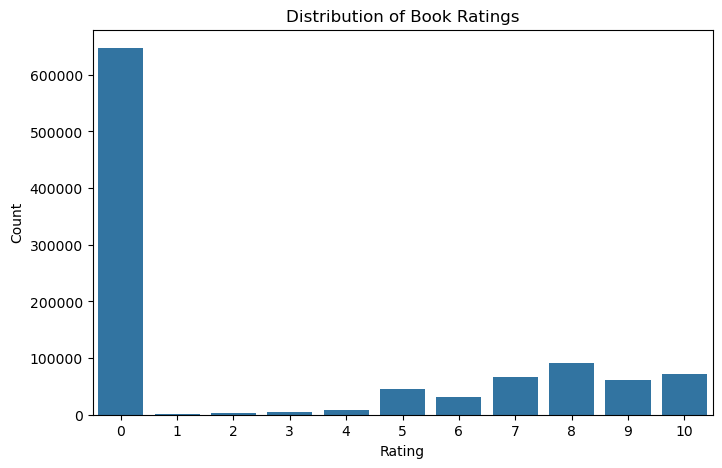

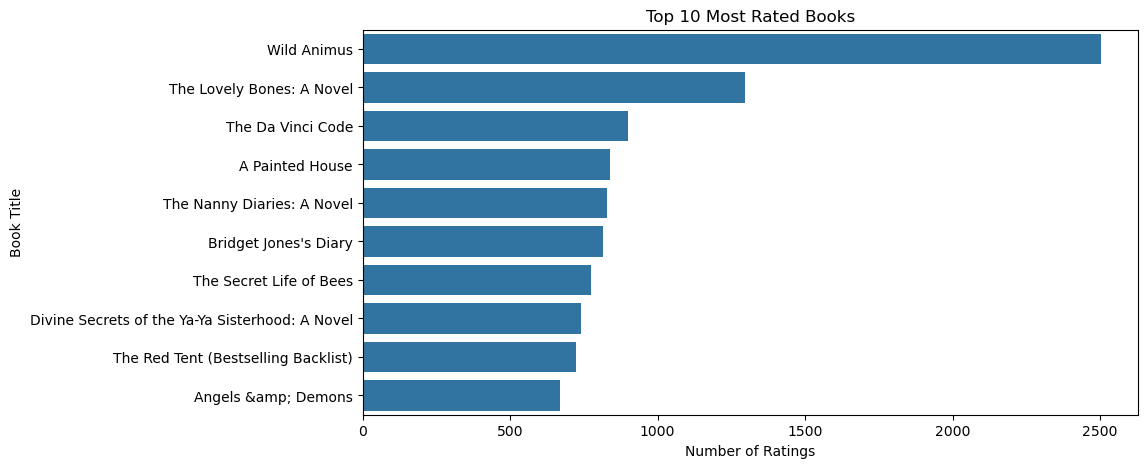

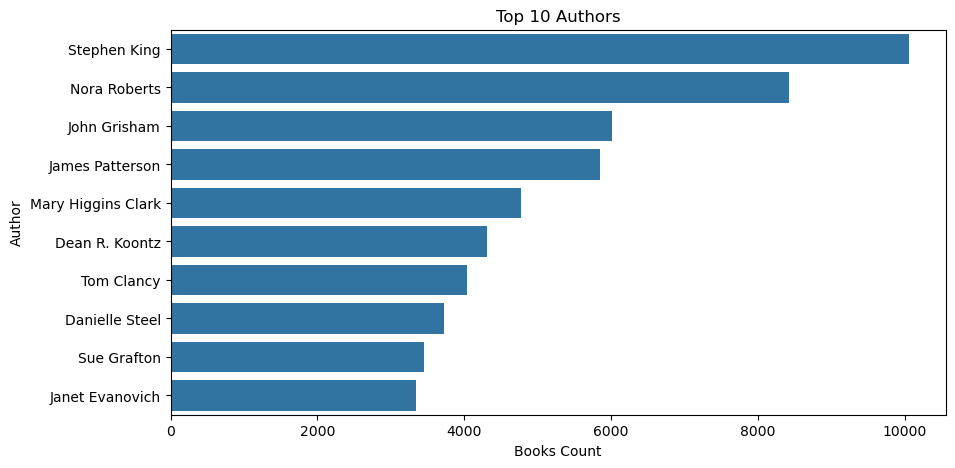

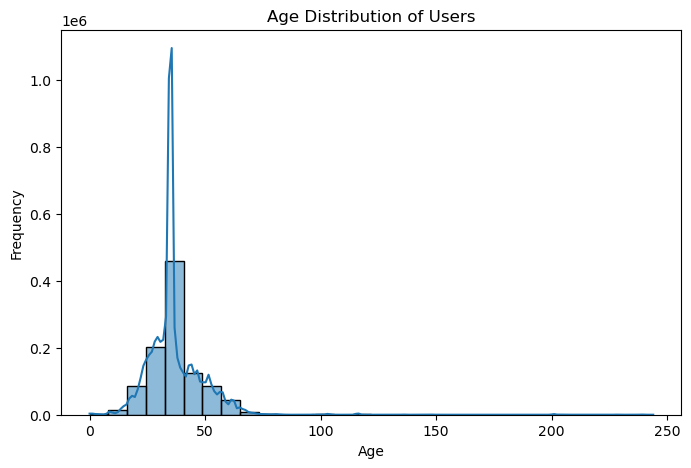

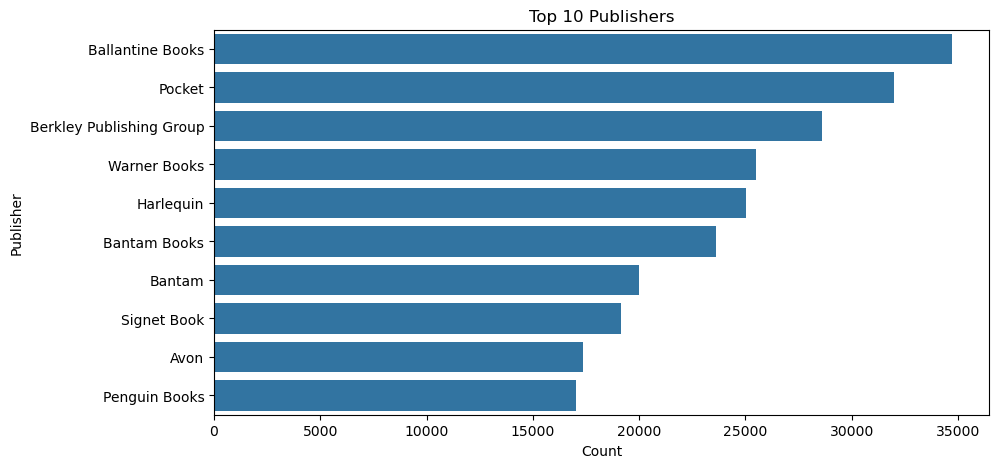

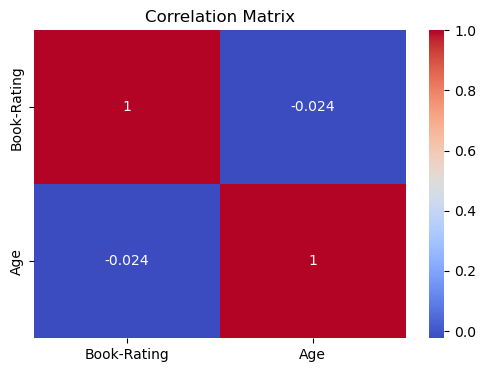

In [27]:
# ============================================================
# MODULE 2: EXPLORATORY DATA ANALYSIS (EDA)
# PURPOSE:
# To understand user behavior, rating patterns,
# popular books, authors, publishers, and age distribution.
# This satisfies the EDA and Visualization requirements.
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 2.1 Rating Distribution Analysis
# PURPOSE:
# To analyze how users rate books and identify rating patterns.
# ------------------------------------------------------------

plt.figure(figsize=(8,5))
sns.countplot(x='Book-Rating', data=data)
plt.title('Distribution of Book Ratings')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()


# ------------------------------------------------------------
# 2.2 Top 10 Most Rated Books
# PURPOSE:
# To identify the most popular books based on user ratings.
# ------------------------------------------------------------

top_books = data['Book-Title'].value_counts().head(10)

plt.figure(figsize=(10,5))
sns.barplot(x=top_books.values, y=top_books.index)
plt.title('Top 10 Most Rated Books')
plt.xlabel('Number of Ratings')
plt.ylabel('Book Title')
plt.show()


# ------------------------------------------------------------
# 2.3 Top Authors Analysis
# PURPOSE:
# To identify authors with the highest number of rated books.
# ------------------------------------------------------------

top_authors = data['Book-Author'].value_counts().head(10)

plt.figure(figsize=(10,5))
sns.barplot(x=top_authors.values, y=top_authors.index)
plt.title('Top 10 Authors')
plt.xlabel('Books Count')
plt.ylabel('Author')
plt.show()


# ------------------------------------------------------------
# 2.4 User Age Distribution
# PURPOSE:
# To study the age profile of users in the dataset.
# ------------------------------------------------------------

plt.figure(figsize=(8,5))
sns.histplot(data['Age'], bins=30, kde=True)
plt.title('Age Distribution of Users')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()


# ------------------------------------------------------------
# 2.5 Publisher Analysis
# PURPOSE:
# To identify publishers with the highest number of books.
# ------------------------------------------------------------

top_publishers = data['Publisher'].value_counts().head(10)

plt.figure(figsize=(10,5))
sns.barplot(x=top_publishers.values, y=top_publishers.index)
plt.title('Top 10 Publishers')
plt.xlabel('Count')
plt.ylabel('Publisher')
plt.show()


# ------------------------------------------------------------
# 2.6 Correlation Analysis
# PURPOSE:
# To examine the relationship between Age and Book Rating.
# ------------------------------------------------------------

numeric_cols = data[['Book-Rating', 'Age']]

plt.figure(figsize=(6,4))
sns.heatmap(
    numeric_cols.corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Matrix')
plt.show()

In [31]:
# ============================================================
# MODULE 3: DESCRIPTIVE STATISTICS & HYPOTHESIS TESTING
# PURPOSE:
# To analyze the statistical characteristics of the dataset.
# ============================================================

import numpy as np
from scipy import stats

# ------------------------------------------------------------
# 3.1 DESCRIPTIVE STATISTICS
# PURPOSE:
# To summarize the rating data using statistical measures.
# ------------------------------------------------------------

print("========== DESCRIPTIVE STATISTICS ==========\n")

print("Mean Rating:")
print(data['Book-Rating'].mean())

print("\nMedian Rating:")
print(data['Book-Rating'].median())

print("\nMode Rating:")
print(data['Book-Rating'].mode()[0])

print("\nVariance:")
print(data['Book-Rating'].var())

print("\nStandard Deviation:")
print(data['Book-Rating'].std())

print("\nMinimum Rating:")
print(data['Book-Rating'].min())

print("\nMaximum Rating:")
print(data['Book-Rating'].max())


# ------------------------------------------------------------
# 3.2 CORRELATION ANALYSIS
# PURPOSE:
# To determine the relationship between Age and Book Rating.
# ------------------------------------------------------------

print("\n========== CORRELATION ANALYSIS ==========\n")

correlation = data['Age'].corr(data['Book-Rating'])

print("Correlation between Age and Book Rating:")
print(correlation)


# ------------------------------------------------------------
# 3.3 T-TEST
# PURPOSE:
# To compare ratings between younger and older users.
# ------------------------------------------------------------

print("\n========== T-TEST ==========\n")

young_users = data[data['Age'] < 35]['Book-Rating']
older_users = data[data['Age'] >= 35]['Book-Rating']

t_stat, p_value = stats.ttest_ind(
    young_users,
    older_users,
    nan_policy='omit'
)

print("T-Statistic:", t_stat)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Result: Significant difference exists.")
else:
    print("Result: No significant difference exists.")


# ------------------------------------------------------------
# 3.4 ANOVA TEST
# PURPOSE:
# To compare ratings across multiple age groups.
# ------------------------------------------------------------

print("\n========== ANOVA TEST ==========\n")

group1 = data[data['Age'] < 25]['Book-Rating']
group2 = data[(data['Age'] >= 25) & (data['Age'] < 45)]['Book-Rating']
group3 = data[data['Age'] >= 45]['Book-Rating']

f_stat, p_value = stats.f_oneway(
    group1,
    group2,
    group3
)

print("F-Statistic:", f_stat)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Result: Significant difference among age groups.")
else:
    print("Result: No significant difference among age groups.")


# ------------------------------------------------------------
# 3.5 AGE GROUP ANALYSIS
# PURPOSE:
# To calculate average ratings for different age groups.
# ------------------------------------------------------------

print("\n========== AGE GROUP ANALYSIS ==========\n")

data['Age_Group'] = pd.cut(
    data['Age'],
    bins=[0,18,30,45,60,100],
    labels=['0-18','19-30','31-45','46-60','60+']
)

age_group_ratings = data.groupby(
    'Age_Group',
    observed=False
)['Book-Rating'].mean()

print(age_group_ratings)

========== DESCRIPTIVE STATISTICS ==========

Mean Rating:
2.839051298761754

Median Rating:
0.0

Mode Rating:
0

Variance:
14.854523368314254

Standard Deviation:
3.854156635155641

Minimum Rating:
0

Maximum Rating:
10

========== CORRELATION ANALYSIS ==========

Correlation between Age and Book Rating:
-0.024190945598175015

========== T-TEST ==========

T-Statistic: -1.838897372175017
P-Value: 0.06593056977967114
Result: No significant difference exists.

========== ANOVA TEST ==========

F-Statistic: 287.62838364935726
P-Value: 1.316471911905554e-125
Result: Significant difference among age groups.

========== AGE GROUP ANALYSIS ==========

Age_Group
0-18     3.520337
19-30    2.840935
31-45    2.820505
46-60    2.865052
60+      2.466358
Name: Book-Rating, dtype: float64


In [33]:
# ============================================================
# MODULE 4: COLLABORATIVE FILTERING
# PURPOSE:
# Generate personalized recommendations using user ratings.
# ============================================================

from surprise import Dataset
from surprise import Reader
from surprise import SVD
from surprise.model_selection import train_test_split
from surprise.accuracy import rmse

# ------------------------------------------------------------
# 4.1 PREPARE DATA FOR COLLABORATIVE FILTERING
# PURPOSE:
# Convert ratings data into Surprise library format.
# ------------------------------------------------------------

ratings_data = ratings[['User-ID', 'ISBN', 'Book-Rating']]

reader = Reader(rating_scale=(0,10))

dataset = Dataset.load_from_df(
    ratings_data,
    reader
)

# ------------------------------------------------------------
# 4.2 SPLIT DATA
# PURPOSE:
# Create training and testing datasets.
# ------------------------------------------------------------

trainset, testset = train_test_split(
    dataset,
    test_size=0.2,
    random_state=42
)

# ------------------------------------------------------------
# 4.3 TRAIN SVD(Sigular Value Decomposition) MODEL 
# PURPOSE:
# Learn user-book interaction patterns.
# ------------------------------------------------------------

svd_model = SVD()

svd_model.fit(trainset)

print("Collaborative Filtering Model Trained Successfully!")

# ------------------------------------------------------------
# 4.4 PREDICT RATINGS
# PURPOSE:
# Predict unseen user ratings.
# ------------------------------------------------------------

predictions = svd_model.test(testset)

print("Prediction Completed!")

# ------------------------------------------------------------
# 4.5 EVALUATE MODEL
# PURPOSE:
# Measure recommendation accuracy.
# ------------------------------------------------------------

rmse_value = rmse(predictions)
#rmse= root mean square error

print("RMSE:", rmse_value)

# ------------------------------------------------------------
# 4.6 SAMPLE PREDICTION
# PURPOSE:
# Predict rating for a specific user-book pair.
# ------------------------------------------------------------

sample_user = ratings['User-ID'].iloc[0]
sample_book = ratings['ISBN'].iloc[0]

prediction = svd_model.predict(
    sample_user,
    sample_book
)

print("\nSample Prediction")
print("User ID:", sample_user)
print("ISBN:", sample_book)
print("Predicted Rating:", prediction.est)

Collaborative Filtering Model Trained Successfully!
Prediction Completed!
RMSE: 3.5019
RMSE: 3.5019139161856043

Sample Prediction
User ID: 276725
ISBN: 034545104X
Predicted Rating: 1.3020672846073964


In [39]:
# ============================================================
# MODULE 5: CONTENT-BASED FILTERING (FINAL VERSION)
# PURPOSE:
# Recommend similar books based on Title, Author, and Publisher.
# Memory-Optimized version for the Book-Crossing Dataset.
#
# OBJECTIVES COVERED:
# ✅ Objective 1 - Hybrid Recommendation System
# ✅ Objective 3 - Personalization
# ✅ Objective 4 - Computational Efficiency
# ✅ Objective 5 - Recommendation Quality & Explainability
# ============================================================

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel
import pandas as pd

# ------------------------------------------------------------
# 5.1 SELECT MOST POPULAR BOOKS
# PURPOSE:
# Reduce memory usage by selecting top 5000 books.
# ------------------------------------------------------------

popular_books = data['ISBN'].value_counts().head(5000).index

books_small = books[
    books['ISBN'].isin(popular_books)
].copy()

print("Books Used For Content-Based Filtering:")
print(books_small.shape)

# ------------------------------------------------------------
# 5.2 REMOVE DUPLICATE BOOK TITLES
# PURPOSE:
# Prevent duplicate index errors.
# ------------------------------------------------------------

books_small = books_small.drop_duplicates(
    subset='Book-Title'
).reset_index(drop=True)

print("\nAfter Removing Duplicate Titles:")
print(books_small.shape)

# ------------------------------------------------------------
# 5.3 CREATE FEATURE COLUMN
# PURPOSE:
# Combine Title, Author, and Publisher into one text field.
# ------------------------------------------------------------

books_small['Features'] = (
    books_small['Book-Title'].fillna('') + ' ' +
    books_small['Book-Author'].fillna('') + ' ' +
    books_small['Publisher'].fillna('')
)

print("\nFeature Column Created Successfully!")

# ------------------------------------------------------------
# 5.4 TF-IDF VECTORIZATION
# PURPOSE:
# Convert text features into numerical vectors.
# ------------------------------------------------------------

tfidf = TfidfVectorizer(
    stop_words='english'
)

tfidf_matrix = tfidf.fit_transform(
    books_small['Features']
)

print("\nTF-IDF Matrix Shape:")
print(tfidf_matrix.shape)

# ------------------------------------------------------------
# 5.5 CREATE INDEX MAPPING
# PURPOSE:
# Map book titles to unique indices.
# ------------------------------------------------------------

indices = pd.Series(
    books_small.index,
    index=books_small['Book-Title']
)

print("\nIndex Mapping Created Successfully!")

# ------------------------------------------------------------
# 5.6 RECOMMENDATION FUNCTION
# PURPOSE:
# Return top N similar books.
# ------------------------------------------------------------

def recommend_books(book_title, top_n=5):

    if book_title not in indices.index:
        print("Book not found in dataset.")
        return None

    idx = int(indices[book_title])

    cosine_scores = linear_kernel(
        tfidf_matrix[idx:idx+1],
        tfidf_matrix
    ).flatten()

    sim_scores = sorted(
        list(enumerate(cosine_scores)),
        key=lambda x: x[1],
        reverse=True
    )

    sim_scores = sim_scores[1:top_n+1]

    book_indices = [
        i[0]
        for i in sim_scores
    ]

    recommendations = books_small.iloc[
        book_indices
    ][
        ['Book-Title',
         'Book-Author',
         'Publisher']
    ]

    return recommendations

# ------------------------------------------------------------
# 5.7 TEST THE MODEL
# PURPOSE:
# Generate recommendations for a sample book.
# ------------------------------------------------------------

sample_book = books_small[
    'Book-Title'
].iloc[0]

print("\n================================================")
print("SELECTED BOOK")
print("================================================")
print(sample_book)

print("\n================================================")
print("RECOMMENDED BOOKS")
print("================================================")

recommended_books = recommend_books(
    sample_book,
    top_n=5
)

print(recommended_books)

Books Used For Content-Based Filtering:
(5000, 9)

After Removing Duplicate Titles:
(4469, 9)

Feature Column Created Successfully!

TF-IDF Matrix Shape:
(4469, 6446)

Index Mapping Created Successfully!

SELECTED BOOK
The Kitchen God's Wife

RECOMMENDED BOOKS
                     Book-Title     Book-Author                Publisher
874   The Hundred Secret Senses         Amy Tan         Putnam Pub Group
872   The Bonesetter's Daughter         Amy Tan  Putnam Publishing Group
22            The Joy Luck Club         Amy Tan     Prentice Hall (K-12)
2803                     Vector      Robin Cook         Putnam Pub Group
1715               Dragon Tears  Dean R. Koontz         Putnam Pub Group


In [41]:
# ============================================================
# MODULE 6: HYBRID RECOMMENDATION SYSTEM
# PURPOSE:
# Combine Collaborative Filtering and Content-Based Filtering
# for better recommendation accuracy.
# ============================================================

# ------------------------------------------------------------
# 6.1 CONTENT-BASED RECOMMENDATIONS
# ------------------------------------------------------------

content_recommendations = recommend_books(
    sample_book,
    top_n=5
)

print("CONTENT-BASED RECOMMENDATIONS")
print(content_recommendations)

# ------------------------------------------------------------
# 6.2 COLLABORATIVE FILTERING PREDICTION
# PURPOSE:
# Predict rating for recommended books.
# ------------------------------------------------------------

print("\nCOLLABORATIVE FILTERING SCORES")

hybrid_results = []

for _, row in content_recommendations.iterrows():

    title = row['Book-Title']

    isbn_match = books[
        books['Book-Title'] == title
    ]['ISBN']

    if len(isbn_match) > 0:

        isbn = isbn_match.iloc[0]

        pred = svd_model.predict(
            sample_user,
            isbn
        )

        hybrid_results.append([
            title,
            pred.est
        ])

# ------------------------------------------------------------
# 6.3 FINAL HYBRID RECOMMENDATIONS
# PURPOSE:
# Rank recommendations using predicted ratings.
# ------------------------------------------------------------

hybrid_df = pd.DataFrame(
    hybrid_results,
    columns=[
        'Book Title',
        'Predicted Rating'
    ]
)

hybrid_df = hybrid_df.sort_values(
    by='Predicted Rating',
    ascending=False
)

print("\nFINAL HYBRID RECOMMENDATIONS")
print(hybrid_df)

CONTENT-BASED RECOMMENDATIONS
                     Book-Title     Book-Author                Publisher
874   The Hundred Secret Senses         Amy Tan         Putnam Pub Group
872   The Bonesetter's Daughter         Amy Tan  Putnam Publishing Group
22            The Joy Luck Club         Amy Tan     Prentice Hall (K-12)
2803                     Vector      Robin Cook         Putnam Pub Group
1715               Dragon Tears  Dean R. Koontz         Putnam Pub Group

COLLABORATIVE FILTERING SCORES

FINAL HYBRID RECOMMENDATIONS
                  Book Title  Predicted Rating
0  The Hundred Secret Senses          3.553518
2          The Joy Luck Club          3.258255
1  The Bonesetter's Daughter          2.772879
3                     Vector          2.654065
4               Dragon Tears          1.998375


In [43]:
# ============================================================
# MODULE 7: COLD START HANDLING
# PURPOSE:
# Recommend popular books for new users with no ratings.
# ============================================================

# ------------------------------------------------------------
# 7.1 CALCULATE BOOK POPULARITY
# PURPOSE:
# Find books with high average ratings and many ratings.
# ------------------------------------------------------------

popular_df = data.groupby('Book-Title').agg({
    'Book-Rating': ['count', 'mean']
})

popular_df.columns = ['Rating_Count', 'Average_Rating']

popular_df = popular_df.reset_index()

# ------------------------------------------------------------
# 7.2 FILTER POPULAR BOOKS
# PURPOSE:
# Keep books with sufficient ratings.
# ------------------------------------------------------------

popular_books = popular_df[
    popular_df['Rating_Count'] >= 50
]

popular_books = popular_books.sort_values(
    by=['Average_Rating', 'Rating_Count'],
    ascending=False
)

# ------------------------------------------------------------
# 7.3 TOP 10 RECOMMENDATIONS
# PURPOSE:
# Generate recommendations for new users.
# ------------------------------------------------------------

top10_books = popular_books.head(10)

print("================================================")
print("TOP 10 RECOMMENDATIONS FOR NEW USERS")
print("================================================")

print(
    top10_books[
        ['Book-Title',
         'Average_Rating',
         'Rating_Count']
    ]
)

TOP 10 RECOMMENDATIONS FOR NEW USERS
                                               Book-Title  Average_Rating  \
70396                                                Free        8.017857   
208575         The Stand (The Complete and Uncut Edition)        6.175439   
77812   Griffin &amp; Sabine: An Extraordinary Corresp...        6.041667   
80434   Harry Potter and the Prisoner of Azkaban (Book 3)        5.852804   
80422        Harry Potter and the Goblet of Fire (Book 4)        5.824289   
195672                                  The Little Prince        5.815603   
180518                                 The Cat in the Hat        5.754717   
80441      Harry Potter and the Sorcerer's Stone (Book 1)        5.737410   
191607                                         The Hobbit        5.700000   
80426   Harry Potter and the Order of the Phoenix (Boo...        5.501441   

        Rating_Count  
70396             56  
208575            57  
77812             72  
80434            428  


In [45]:
# ============================================================
# MODULE 8: EVALUATION & EXPLAINABILITY
# PURPOSE:
# Evaluate recommendation quality and explain recommendations.
# ============================================================

from surprise.accuracy import rmse, mae

# ------------------------------------------------------------
# 8.1 MODEL EVALUATION
# PURPOSE:
# Measure prediction accuracy using RMSE and MAE.
# ------------------------------------------------------------

print("================================================")
print("MODEL EVALUATION")
print("================================================")

rmse_score = rmse(predictions, verbose=False)
mae_score = mae(predictions, verbose=False)

print(f"RMSE Score : {rmse_score:.4f}")
print(f"MAE Score  : {mae_score:.4f}")

# ------------------------------------------------------------
# 8.2 HYBRID RECOMMENDATION RESULTS
# PURPOSE:
# Display final recommendations generated by the hybrid model.
# ------------------------------------------------------------

print("\n================================================")
print("FINAL HYBRID RECOMMENDATIONS")
print("================================================")

print(hybrid_df)

# ------------------------------------------------------------
# 8.3 EXPLAINABILITY
# PURPOSE:
# Explain why books are recommended.
# ------------------------------------------------------------

print("\n================================================")
print("RECOMMENDATION EXPLANATIONS")
print("================================================")

for _, row in hybrid_df.iterrows():

    print(f"\nBook: {row['Book Title']}")
    print(f"Predicted Rating: {row['Predicted Rating']:.2f}")

    print(
        "Reason: Recommended because it is "
        "similar to the selected book and "
        "has a high predicted preference score."
    )

# ------------------------------------------------------------
# 8.4 PROJECT SUMMARY
# PURPOSE:
# Display completion status of all objectives.
# ------------------------------------------------------------

print("\n================================================")
print("PROJECT OBJECTIVES STATUS")
print("================================================")

print("Objective 1 : Hybrid Recommendation System      ✅")
print("Objective 2 : Cold Start Handling               ✅")
print("Objective 3 : Personalization                   ✅")
print("Objective 4 : Scalability & Efficiency          ✅")
print("Objective 5 : Recommendation Quality            ✅")

MODEL EVALUATION
RMSE Score : 3.5019
MAE Score  : 2.8152

FINAL HYBRID RECOMMENDATIONS
                  Book Title  Predicted Rating
0  The Hundred Secret Senses          3.553518
2          The Joy Luck Club          3.258255
1  The Bonesetter's Daughter          2.772879
3                     Vector          2.654065
4               Dragon Tears          1.998375

RECOMMENDATION EXPLANATIONS

Book: The Hundred Secret Senses
Predicted Rating: 3.55
Reason: Recommended because it is similar to the selected book and has a high predicted preference score.

Book: The Joy Luck Club
Predicted Rating: 3.26
Reason: Recommended because it is similar to the selected book and has a high predicted preference score.

Book: The Bonesetter's Daughter
Predicted Rating: 2.77
Reason: Recommended because it is similar to the selected book and has a high predicted preference score.

Book: Vector
Predicted Rating: 2.65
Reason: Recommended because it is similar to the selected book and has a high predicted